In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.cluster import KMeans

In [ ]:
iris = load_iris()
x = iris.data[:,[2,3]]
y= iris.target
print(iris.feature_names[2])
print(iris.feature_names[3])

petal length (cm)
petal width (cm)


In [ ]:
model = KMeans(n_clusters =3, random_state=42, n_init =10)
model.fit_predict(x)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

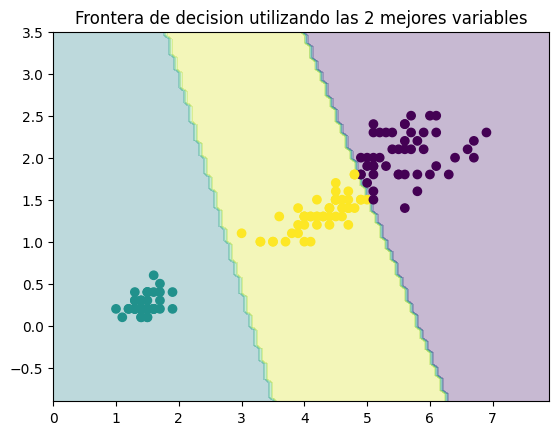

In [ ]:
DecisionBoundaryDisplay.from_estimator(model, x, response_method= "predict", alpha = 0.3)
plt.title("Frontera de decision utilizando las 2 mejores variables")
plt.scatter(x[:,0],x[:,1], c= model.labels_)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler #Normalizar la data
from sklearn.datasets import load_iris #Dataset
from sklearn.decomposition import PCA #Reducción de dimensiones
from sklearn.cluster import KMeans #Algoritmo de clustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score #Metricas para evaluar

In [ ]:
x_scaled = StandardScaler().fit_transform(x) # Escalamos los datos obtenidos (para el entrenamiento)
x_scaled

array([[-9.00681170e-01,  1.01900435e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00, -1.31979479e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.38535265e+00,  3.28414053e-01, -1.39706395e+00,
        -1.31544430e+00],
       [-1.50652052e+00,  9.82172869e-02, -1.28338910e+00,
        -1.31544430e+00],
       [-1.02184904e+00,  1.24920112e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-5.37177559e-01,  1.93979142e+00, -1.16971425e+00,
        -1.05217993e+00],
       [-1.50652052e+00,  7.88807586e-01, -1.34022653e+00,
        -1.18381211e+00],
       [-1.02184904e+00,  7.88807586e-01, -1.28338910e+00,
        -1.31544430e+00],
       [-1.74885626e+00, -3.62176246e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00,  9.82172869e-02, -1.28338910e+00,
        -1.44707648e+00],
       [-5.37177559e-01,  1.47939788e+00, -1.28338910e+00,
        -1.31544430e+00],
       [-1.26418478e+00,  7.88807586e-01, -1.22655167e+00,
      

In [ ]:
x_scaled = StandardScaler().fit_transform(x) # Escalamos los datos obtenidos (para el entrenamiento)
x_scaled

array([[-9.00681170e-01,  1.01900435e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00, -1.31979479e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.38535265e+00,  3.28414053e-01, -1.39706395e+00,
        -1.31544430e+00],
       [-1.50652052e+00,  9.82172869e-02, -1.28338910e+00,
        -1.31544430e+00],
       [-1.02184904e+00,  1.24920112e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-5.37177559e-01,  1.93979142e+00, -1.16971425e+00,
        -1.05217993e+00],
       [-1.50652052e+00,  7.88807586e-01, -1.34022653e+00,
        -1.18381211e+00],
       [-1.02184904e+00,  7.88807586e-01, -1.28338910e+00,
        -1.31544430e+00],
       [-1.74885626e+00, -3.62176246e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00,  9.82172869e-02, -1.28338910e+00,
        -1.44707648e+00],
       [-5.37177559e-01,  1.47939788e+00, -1.28338910e+00,
        -1.31544430e+00],
       [-1.26418478e+00,  7.88807586e-01, -1.22655167e+00,
      

In [ ]:
x_2d = PCA(n_components=2).fit_transform(x_scaled) #Reducimos a 2d las 4 columnas (Para graficar los datos)
x_2d

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,

In [ ]:
model = KMeans(n_clusters= 3, random_state= 42, n_init = 10)
model.fit(x_2d)

KMeans(n_clusters=3, n_init=10, random_state=42)

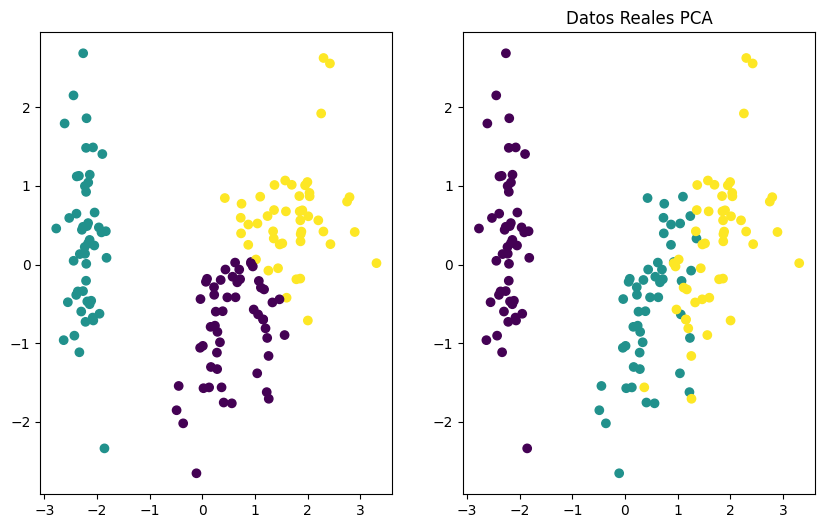

In [ ]:
# GRAFICANDO DATOS CON LA PCA APLICADA SOBRE LA DATA ESCALADA ANTERIORMENTE

plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.scatter(x_2d[:,0], x_2d[:,1], c=model.labels_)

plt.subplot(1,2,2)
plt.title('Datos Reales PCA')
plt.scatter(x_2d[:,0], x_2d[:,1], c=y)
plt.show()

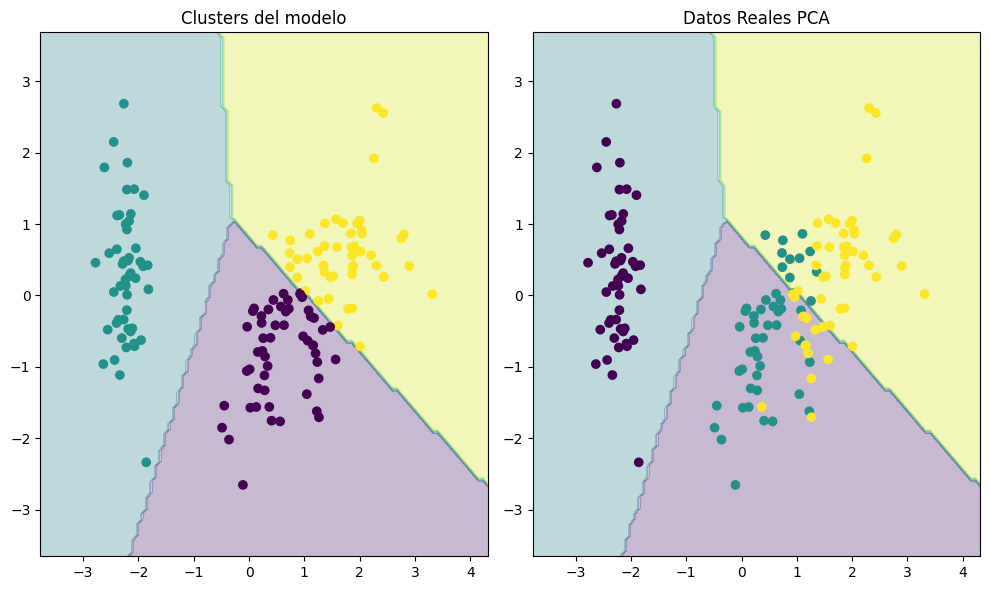

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
DecisionBoundaryDisplay.from_estimator(model, x_2d,response_method="predict",  alpha=0.3, ax=ax1 )
ax1.scatter(x_2d[:, 0], x_2d[:, 1], c=model.labels_)
ax1.set_title("Clusters del modelo")

DecisionBoundaryDisplay.from_estimator( model, x_2d,response_method="predict", alpha=0.3, ax=ax2)
ax2.scatter(x_2d[:, 0], x_2d[:, 1], c=y)
ax2.set_title("Datos Reales PCA")

plt.tight_layout()
plt.show()

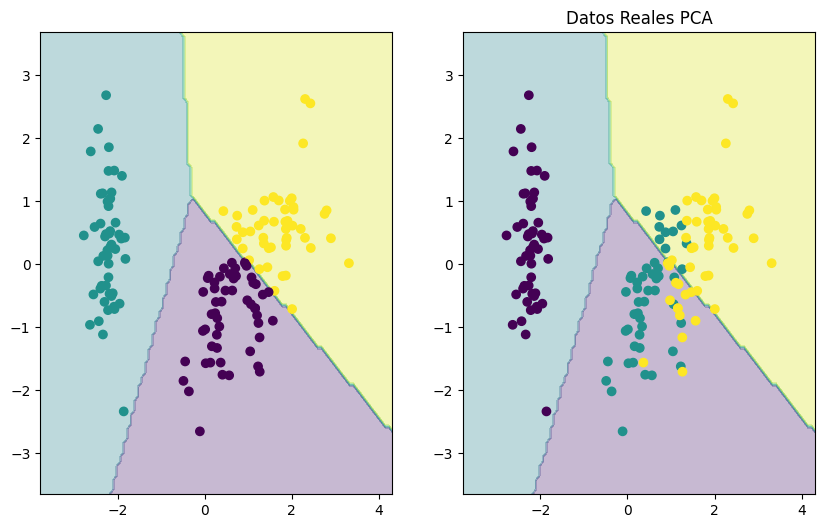

In [ ]:
plt.figure(figsize=(10,6))

plt.subplot(1,2,1)
DecisionBoundaryDisplay.from_estimator(model, x_2d, response_method="predict", alpha=0.3, ax=plt.gca())
plt.scatter(x_2d[:,0], x_2d[:,1], c=model.labels_)

plt.subplot(1,2,2)
plt.title('Datos Reales PCA')
DecisionBoundaryDisplay.from_estimator(model, x_2d, response_method="predict", alpha=0.3, ax=plt.gca())
plt.scatter(x_2d[:,0], x_2d[:,1], c=y)

plt.show()